NAME : RIYA CHOUDHARY, ROLL NO : 51, SECTION : B

# LAB SHEET No. 6 - Predictive Analytics using Linear Regression and Model Performance Evaluation



### Step 1: Import Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load the Dataset


In [ ]:
import os

DATA_PATH = "/content/Advertising.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,ID,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


### Step 3: Data Preprocessing & Exploratory Data Analysis

In [ ]:
print("Dataset info:\n")
df.info()

print("\nMissing values per column:\n")
print(df.isnull().sum())

df = df.dropna().drop_duplicates()

print(f"\nCleaned dataset shape: {df.shape}\n")
df.describe()

Dataset info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         200 non-null    int64  
 1   TV         200 non-null    float64
 2   Radio      200 non-null    float64
 3   Newspaper  200 non-null    float64
 4   Sales      200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Missing values per column:

ID           0
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Cleaned dataset shape: (200, 5)



,ID,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


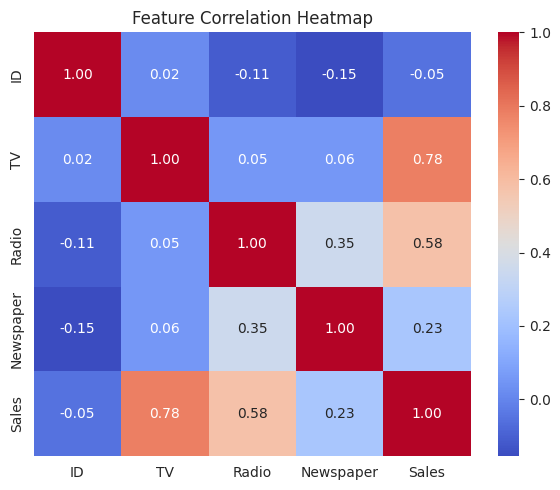

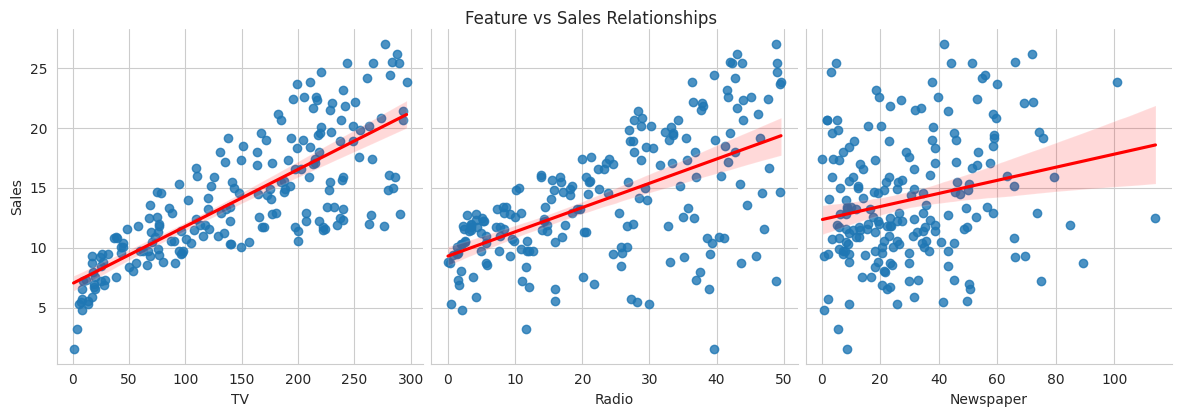

In [ ]:
# Correlation heatmap to understand relationships
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Pairwise scatter plots
sns.pairplot(df, x_vars=["TV", "Radio", "Newspaper"], y_vars="Sales",
             kind="reg", height=4, plot_kws={"line_kws": {"color": "red"}})
plt.suptitle("Feature vs Sales Relationships", y=1.02)
plt.show()

### Step 4: Select Features & Split into Train/Test Sets

In [ ]:
feature_cols = ["TV", "Radio", "Newspaper"]
target_col = "Sales"

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (160, 3)
Testing set size: (40, 3)


### Step 5: Train the Linear Regression Model

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Model trained successfully.")
print(f"Intercept (b0): {lr_model.intercept_:.4f}")
print("\nCoefficients:")
for feature, coef in zip(feature_cols, lr_model.coef_):
    print(f"  {feature}: {coef:.4f}")

Model trained successfully.
Intercept (b0): 2.9791

Coefficients:
  TV: 0.0447
  Radio: 0.1892
  Newspaper: 0.0028


### Step 6: Predict on Test Data

In [ ]:
y_pred = lr_model.predict(X_test)

results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": np.round(y_pred, 2),
})
results_df["Error"] = np.round(results_df["Actual"] - results_df["Predicted"], 2)
results_df.head(10)

,Actual,Predicted,Error
0,16.9,16.41,0.49
1,22.4,20.89,1.51
2,21.4,21.55,-0.15
3,7.3,10.61,-3.31
4,24.7,22.11,2.59
5,12.6,13.11,-0.51
6,22.3,21.06,1.24
7,8.4,7.46,0.94
8,11.5,13.61,-2.11
9,14.9,15.16,-0.26


### Step 7: Visualize Actual vs Predicted

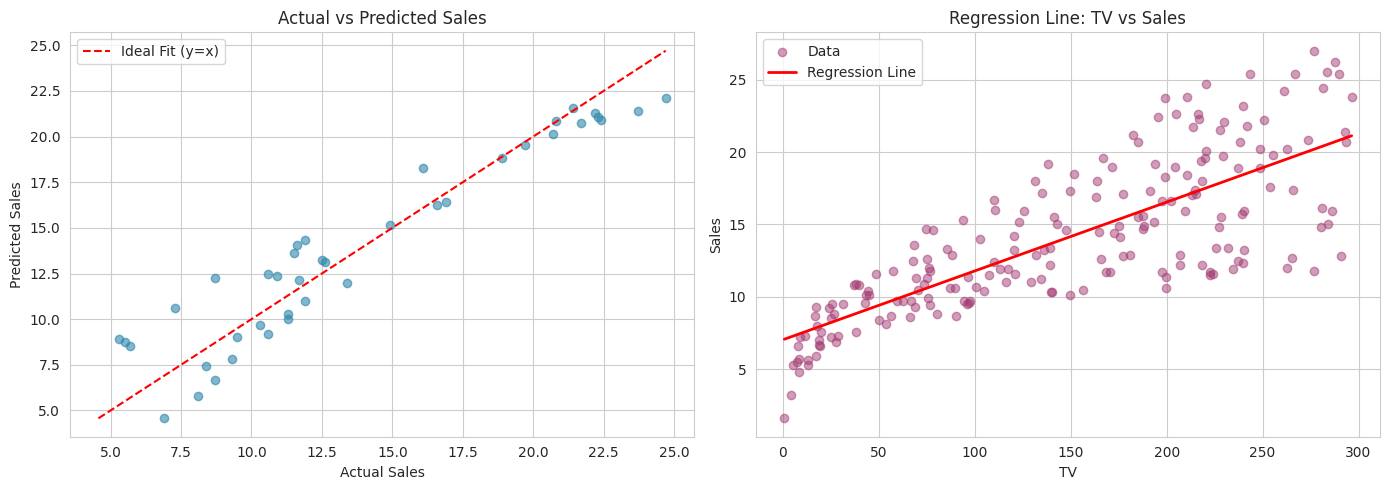

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted scatter with ideal-fit line
axes[0].scatter(y_test, y_pred, alpha=0.6, color="#2E86AB")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", label="Ideal Fit (y=x)")
axes[0].set_xlabel("Actual Sales")
axes[0].set_ylabel("Predicted Sales")
axes[0].set_title("Actual vs Predicted Sales")
axes[0].legend()

# 2. Regression line for the strongest single predictor (TV)
strongest_feature = df[feature_cols].corrwith(df[target_col]).abs().idxmax()
axes[1].scatter(df[strongest_feature], df[target_col], alpha=0.5, color="#A23B72", label="Data")

single_lr = LinearRegression().fit(df[[strongest_feature]], df[target_col])
x_line = np.linspace(df[strongest_feature].min(), df[strongest_feature].max(), 100)
y_line = single_lr.predict(pd.DataFrame({strongest_feature: x_line}))
axes[1].plot(x_line, y_line, color="red", linewidth=2, label="Regression Line")
axes[1].set_xlabel(strongest_feature)
axes[1].set_ylabel("Sales")
axes[1].set_title(f"Regression Line: {strongest_feature} vs Sales")
axes[1].legend()

plt.tight_layout()
plt.show()

### Step 8: Evaluate Model Performance

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("REGRESSION MODEL EVALUATION")
print("-" * 40)
print(f"Mean Absolute Error (MAE) : {mae:.4f}")
print(f"Mean Squared Error (MSE)  : {mse:.4f}")
print(f"Root Mean Squared Error   : {rmse:.4f}")
print(f"R-squared (R2 Score)      : {r2:.4f}")
print(f"\nInterpretation: the model explains {r2:.1%} of the variance in Sales.")

REGRESSION MODEL EVALUATION
----------------------------------------
Mean Absolute Error (MAE) : 1.4608
Mean Squared Error (MSE)  : 3.1741
Root Mean Squared Error   : 1.7816
R-squared (R2 Score)      : 0.8994

Interpretation: the model explains 89.9% of the variance in Sales.


### Step 9: Analyze Regression Coefficients

/tmp/ipykernel_2751/3147312925.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="Coefficient", y="Feature", palette="viridis")


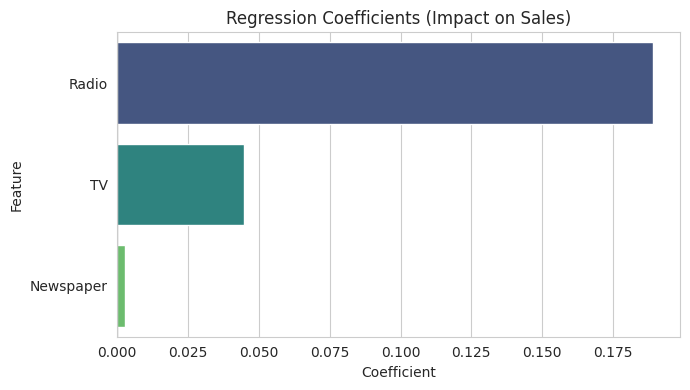

,Feature,Coefficient
1,Radio,0.189195
0,TV,0.044730
2,Newspaper,0.002761


In [ ]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": lr_model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", palette="viridis")
plt.title("Regression Coefficients (Impact on Sales)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df

### Step 10: Interpretation & Suitability Discussion
Run the cell below for an auto-generated interpretation summary.

In [ ]:
strongest = coef_df.iloc[0]

print("INTERPRETATION SUMMARY")
print("-" * 40)
print(f"- Every 1-unit increase in {strongest['Feature']} spend is associated with a change")
print(f"  of {strongest['Coefficient']:.4f} units in Sales, holding other features constant.")
print(f"- Model fit (R2 = {r2:.3f}): {'strong' if r2 > 0.8 else 'moderate' if r2 > 0.5 else 'weak'} fit for this data.")
print(f"- Average prediction error (MAE): {mae:.2f} units of Sales.")
print("\nSuitability: Linear Regression works well here because Sales shows a roughly")
print("linear relationship with the advertising spend features, and the model provides")
print("clear, interpretable coefficients showing each channel's contribution to Sales -")
print("useful for budget allocation decisions across marketing channels.")

INTERPRETATION SUMMARY
----------------------------------------
- Every 1-unit increase in Radio spend is associated with a change
  of 0.1892 units in Sales, holding other features constant.
- Model fit (R2 = 0.899): strong fit for this data.
- Average prediction error (MAE): 1.46 units of Sales.

Suitability: Linear Regression works well here because Sales shows a roughly
linear relationship with the advertising spend features, and the model provides
clear, interpretable coefficients showing each channel's contribution to Sales -
useful for budget allocation decisions across marketing channels.
